# Produtos e categorias: atraso e avaliação

Como atraso e avaliação se relacionam nos top 10 produtos e categorias? Compara rankings por avaliações ruins e por atraso, com mínimos totais de 10 e 30 pedidos.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

RAIZ_PROJETO = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / 'executar_pipeline.py').is_file() and (p / 'src').is_dir()),
    None
)
if RAIZ_PROJETO is None:
    raise FileNotFoundError('Abra o notebook dentro da pasta do projeto.')

# Os resumos de outputs/tabelas/parquet não têm o detalhe necessário.
PASTA_BASES = RAIZ_PROJETO / 'data' / 'processed'
df_pedidos = pd.read_parquet(PASTA_BASES / 'base_analitica_pedidos.parquet')
assert df_pedidos['order_id'].notna().all()
assert df_pedidos['order_id'].is_unique
pd.set_option('display.max_columns', None)


In [2]:
df_itens = pd.read_parquet(PASTA_BASES / 'itens_pedidos.parquet')
assert df_itens[['order_id', 'order_item_id', 'product_id']].notna().all().all()
assert not df_itens.duplicated(['order_id', 'order_item_id']).any()
assert df_itens['order_id'].isin(df_pedidos['order_id']).all()

# Conta todos os itens ANTES de filtrar entrega ou avaliação.
contagem_itens = df_itens.groupby('order_id').size()
ids_um_item = contagem_itens.loc[contagem_itens.eq(1)].index
itens_um_item = df_itens.loc[
    df_itens['order_id'].isin(ids_um_item),
    ['order_id', 'product_id', 'product_category_name']
]
pedidos_elegiveis = df_pedidos.loc[
    df_pedidos['pedido_entregue'].eq(True)
    & df_pedidos['review_score'].isin([1, 2, 3, 4, 5]),
    ['order_id', 'review_score', 'is_late']
]
df_produtos_analise = itens_um_item.merge(
    pedidos_elegiveis, on='order_id', how='inner', validate='one_to_one'
)
assert df_produtos_analise['order_id'].is_unique
assert len(df_produtos_analise) == pedidos_elegiveis['order_id'].isin(ids_um_item).sum()
df_produtos_analise['categoria'] = (
    df_produtos_analise['product_category_name'].fillna('sem_categoria')
)


In [3]:
def classificar_entrega(serie):
    resultado = pd.Series('Sem informação', index=serie.index, dtype='string')
    resultado.loc[serie.eq(False).fillna(False)] = 'No prazo'
    resultado.loc[serie.eq(True).fillna(False)] = 'Atrasado'
    return resultado


def resumir_avaliacoes(dados, grupo):
    base = dados.assign(
        review_ruim=dados['review_score'].isin([1, 2]),
        review_neutra=dados['review_score'].eq(3),
        review_boa=dados['review_score'].isin([4, 5])
    )
    resumo = base.groupby(
        [grupo, 'situacao_entrega'], as_index=False, observed=True, dropna=False
    ).agg(
        quantidade_pedidos=('order_id', 'nunique'),
        nota_media=('review_score', 'mean'),
        reviews_ruins=('review_ruim', 'sum'),
        reviews_neutras=('review_neutra', 'sum'),
        reviews_boas=('review_boa', 'sum')
    )
    for tipo in ('ruins', 'neutras', 'boas'):
        resumo[f'pct_reviews_{tipo}'] = (
            resumo[f'reviews_{tipo}'] / resumo['quantidade_pedidos']
        )
    assert resumo['quantidade_pedidos'].sum() == len(base)
    assert resumo[['reviews_ruins', 'reviews_neutras', 'reviews_boas']].sum(axis=1).eq(
        resumo['quantidade_pedidos']
    ).all()
    return resumo


def formatar_resultado(tabela):
    formatos = {}
    for coluna in tabela.columns:
        if coluna.startswith('pct_') or coluna in ('taxa_recompra', 'taxa_geral_situacao'):
            formatos[coluna] = '{:.2%}'
        elif coluna.endswith('_pp'):
            formatos[coluna] = '{:+.2f} pontos percentuais'
        elif coluna == 'nota_media':
            formatos[coluna] = '{:.2f}'
        elif pd.api.types.is_integer_dtype(tabela[coluna]):
            formatos[coluna] = '{:,.0f}'
    return tabela.style.format(
        formatos, na_rep='Sem informação', decimal=',', thousands='.'
    )


In [4]:
# Reutiliza o ranking calculado no notebook 03, sem refazer sua seleção.
PASTA_RANKINGS = RAIZ_PROJETO / 'outputs' / 'tabelas' / 'parquet'
df_ranking_produtos = pd.read_parquet(PASTA_RANKINGS / '03_ranking_produtos.parquet')
df_ranking_categorias = pd.read_parquet(PASTA_RANKINGS / '03_ranking_categorias.parquet')
assert df_ranking_produtos['product_id'].is_unique
assert df_ranking_categorias['categoria_analise'].is_unique
assert df_ranking_produtos['quantidade_pedidos'].ge(5).all()
assert df_ranking_categorias['quantidade_pedidos'].ge(20).all()

# O head(10) seleciona grupos, não linhas após a separação por prazo.
df_top_produtos = df_ranking_produtos.sort_values('posicao').head(10).copy()
df_top_categorias = (
    df_ranking_categorias.sort_values('posicao').head(10)
    .rename(columns={'categoria_analise': 'categoria'}).copy()
)
df_produtos_analise['situacao_entrega'] = classificar_entrega(df_produtos_analise['is_late'])


def detalhar_top(ranking, grupo):
    dados = df_produtos_analise.loc[df_produtos_analise[grupo].isin(ranking[grupo])]
    resumo = resumir_avaliacoes(dados, grupo)
    # Detecta rankings que não correspondam mais às bases detalhadas.
    totais = resumo.groupby(grupo)[['quantidade_pedidos', 'reviews_ruins']].sum()
    esperado = ranking.set_index(grupo)[['quantidade_pedidos', 'reviews_ruins']]
    pd.testing.assert_frame_equal(
        totais.reindex(esperado.index), esperado, check_dtype=False, check_exact=True
    )
    metadados = ranking[[
        grupo, 'posicao', 'quantidade_pedidos', 'pct_reviews_ruins'
    ]].rename(columns={
        'quantidade_pedidos': 'pedidos_geral',
        'pct_reviews_ruins': 'pct_reviews_ruins_geral'
    })
    # Após conferir o ranking completo, usa apenas situações com prazo conhecido.
    resumo = resumo.loc[resumo['situacao_entrega'].isin(['Atrasado', 'No prazo'])].copy()
    resumo['pedidos_com_prazo'] = resumo.groupby(grupo)['quantidade_pedidos'].transform('sum')
    resumo['pct_pedidos_situacao'] = (
        resumo['quantidade_pedidos'] / resumo['pedidos_com_prazo']
    )
    assert resumo['pct_pedidos_situacao'].between(0, 1).all()
    assert resumo.groupby(grupo)['pct_pedidos_situacao'].sum().sub(1).abs().lt(1e-10).all()
    resultado = resumo.merge(metadados, on=grupo, how='left', validate='many_to_one')
    colunas_inicio = [
        'posicao', grupo, 'pedidos_geral', 'pct_reviews_ruins_geral',
        'situacao_entrega', 'pct_pedidos_situacao'
    ]
    return resultado[
        colunas_inicio + [c for c in resultado.columns if c not in colunas_inicio]
    ].sort_values(['posicao', 'situacao_entrega']).reset_index(drop=True)


df_produtos_atraso_avaliacao = detalhar_top(df_top_produtos, 'product_id')
df_categorias_atraso_avaliacao = detalhar_top(df_top_categorias, 'categoria')


def selecionar_top_atraso(ranking, grupo):
    # Seleciona por atraso entre TODOS os grupos elegíveis, não só o top de notas ruins.
    detalhes = detalhar_top(ranking, grupo)
    taxas = detalhes.assign(
        quantidade_atrasados=detalhes['quantidade_pedidos'].where(
            detalhes['situacao_entrega'].eq('Atrasado'), 0
        )
    ).groupby(grupo, as_index=False).agg(
        quantidade_atrasados=('quantidade_atrasados', 'sum'),
        pedidos_com_prazo=('pedidos_com_prazo', 'first')
    )
    taxas['taxa_atraso'] = taxas['quantidade_atrasados'] / taxas['pedidos_com_prazo']
    top = (
        ranking.merge(taxas, on=grupo, how='inner', validate='one_to_one')
        .sort_values(
            ['taxa_atraso', 'pedidos_com_prazo', grupo],
            ascending=[False, False, True]
        )
        .head(10)
        .copy()
    )
    # Nas novas tabelas, a posição corresponde ao ranking de atraso.
    top['posicao'] = range(1, len(top) + 1)
    return top


df_top_produtos_por_atraso = selecionar_top_atraso(df_ranking_produtos, 'product_id')
df_top_categorias_por_atraso = selecionar_top_atraso(
    df_ranking_categorias.rename(columns={'categoria_analise': 'categoria'}), 'categoria'
)
df_produtos_maiores_atrasos = detalhar_top(df_top_produtos_por_atraso, 'product_id')
df_categorias_maiores_atrasos = detalhar_top(df_top_categorias_por_atraso, 'categoria')
assert df_produtos_maiores_atrasos.columns.equals(df_produtos_atraso_avaliacao.columns)
assert df_categorias_maiores_atrasos.columns.equals(df_categorias_atraso_avaliacao.columns)


In [5]:
display(formatar_resultado(df_categorias_atraso_avaliacao))
display(formatar_resultado(df_produtos_atraso_avaliacao))
display(formatar_resultado(df_categorias_maiores_atrasos))
display(formatar_resultado(df_produtos_maiores_atrasos))


,posicao,categoria,pedidos_geral,pct_reviews_ruins_geral,situacao_entrega,pct_pedidos_situacao,quantidade_pedidos,nota_media,reviews_ruins,reviews_neutras,reviews_boas,pct_reviews_ruins,pct_reviews_neutras,pct_reviews_boas,pedidos_com_prazo
0,1,fashion_roupa_masculina,91,"21,98%",Atrasado,"4,40%",4,"2,00",3,0,1,"75,00%","0,00%","25,00%",91
1,1,fashion_roupa_masculina,91,"21,98%",No prazo,"95,60%",87,"3,92",17,7,63,"19,54%","8,05%","72,41%",91
2,2,audio,329,"21,88%",Atrasado,"12,16%",40,"1,73",31,4,5,"77,50%","10,00%","12,50%",329
3,2,audio,329,"21,88%",No prazo,"87,84%",289,"4,13",41,27,221,"14,19%","9,34%","76,47%",329
4,3,moveis_colchao_e_estofado,37,"18,92%",Atrasado,"13,51%",5,"2,20",3,1,1,"60,00%","20,00%","20,00%",37
5,3,moveis_colchao_e_estofado,37,"18,92%",No prazo,"86,49%",32,"4,16",4,2,26,"12,50%","6,25%","81,25%",37
6,4,moveis_escritorio,1.010,"18,81%",Atrasado,"8,51%",86,"2,38",53,8,25,"61,63%","9,30%","29,07%",1.010
7,4,moveis_escritorio,1.010,"18,81%",No prazo,"91,49%",924,"3,90",137,134,653,"14,83%","14,50%","70,67%",1.010
8,5,fashion_underwear_e_moda_praia,110,"17,27%",Atrasado,"9,09%",10,"1,70",8,1,1,"80,00%","10,00%","10,00%",110
9,5,fashion_underwear_e_moda_praia,110,"17,27%",No prazo,"90,91%",100,"4,19",11,7,82,"11,00%","7,00%","82,00%",110


,posicao,product_id,pedidos_geral,pct_reviews_ruins_geral,situacao_entrega,pct_pedidos_situacao,quantidade_pedidos,nota_media,reviews_ruins,reviews_neutras,reviews_boas,pct_reviews_ruins,pct_reviews_neutras,pct_reviews_boas,pedidos_com_prazo
0,1,c230b471b7e21ff9060e68ee154afd70,7,"100,00%",No prazo,"100,00%",7,"1,29",7,0,0,"100,00%","0,00%","0,00%",7
1,2,ffedbd68fa6f44e788ff6c2db8094715,5,"100,00%",No prazo,"100,00%",5,"1,00",5,0,0,"100,00%","0,00%","0,00%",5
2,3,fd0065af7f09af4b82a0ca8f3eed1852,10,"90,00%",Atrasado,"90,00%",9,"1,00",9,0,0,"100,00%","0,00%","0,00%",10
3,3,fd0065af7f09af4b82a0ca8f3eed1852,10,"90,00%",No prazo,"10,00%",1,"3,00",0,1,0,"0,00%","100,00%","0,00%",10
4,4,6fb42788c5ef9affaa2fec30ca8b6053,8,"87,50%",No prazo,"100,00%",8,"1,88",7,0,1,"87,50%","0,00%","12,50%",8
5,5,2ac71e1960d313613f4f4cd468c602cb,7,"85,71%",No prazo,"100,00%",7,"1,43",6,0,1,"85,71%","0,00%","14,29%",7
6,6,8b52d90d2e8716dad633486c6cc94ecf,7,"85,71%",Atrasado,"28,57%",2,"2,00",1,1,0,"50,00%","50,00%","0,00%",7
7,6,8b52d90d2e8716dad633486c6cc94ecf,7,"85,71%",No prazo,"71,43%",5,"1,20",5,0,0,"100,00%","0,00%","0,00%",7
8,7,cd46a885543f0e169a49f1eb25c04e43,27,"85,19%",No prazo,"100,00%",27,"1,48",23,1,3,"85,19%","3,70%","11,11%",27
9,8,6d2fde7d12bb6ff367dbda120ba8828e,6,"83,33%",No prazo,"100,00%",6,"1,67",5,1,0,"83,33%","16,67%","0,00%",6


,posicao,categoria,pedidos_geral,pct_reviews_ruins_geral,situacao_entrega,pct_pedidos_situacao,quantidade_pedidos,nota_media,reviews_ruins,reviews_neutras,reviews_boas,pct_reviews_ruins,pct_reviews_neutras,pct_reviews_boas,pedidos_com_prazo
0,1,moveis_colchao_e_estofado,37,"18,92%",Atrasado,"13,51%",5,"2,20",3,1,1,"60,00%","20,00%","20,00%",37
1,1,moveis_colchao_e_estofado,37,"18,92%",No prazo,"86,49%",32,"4,16",4,2,26,"12,50%","6,25%","81,25%",37
2,2,audio,329,"21,88%",Atrasado,"12,16%",40,"1,73",31,4,5,"77,50%","10,00%","12,50%",329
3,2,audio,329,"21,88%",No prazo,"87,84%",289,"4,13",41,27,221,"14,19%","9,34%","76,47%",329
4,3,casa_conforto,315,"15,87%",Atrasado,"10,16%",32,"2,25",18,7,7,"56,25%","21,88%","21,88%",315
5,3,casa_conforto,315,"15,87%",No prazo,"89,84%",283,"4,22",32,32,219,"11,31%","11,31%","77,39%",315
6,4,fashion_underwear_e_moda_praia,110,"17,27%",Atrasado,"9,09%",10,"1,70",8,1,1,"80,00%","10,00%","10,00%",110
7,4,fashion_underwear_e_moda_praia,110,"17,27%",No prazo,"90,91%",100,"4,19",11,7,82,"11,00%","7,00%","82,00%",110
8,5,livros_tecnicos,243,"8,23%",Atrasado,"8,64%",21,"3,19",7,3,11,"33,33%","14,29%","52,38%",243
9,5,livros_tecnicos,243,"8,23%",No prazo,"91,36%",222,"4,59",13,5,204,"5,86%","2,25%","91,89%",243


,posicao,product_id,pedidos_geral,pct_reviews_ruins_geral,situacao_entrega,pct_pedidos_situacao,quantidade_pedidos,nota_media,reviews_ruins,reviews_neutras,reviews_boas,pct_reviews_ruins,pct_reviews_neutras,pct_reviews_boas,pedidos_com_prazo
0,1,fd0065af7f09af4b82a0ca8f3eed1852,10,"90,00%",Atrasado,"90,00%",9,"1,00",9,0,0,"100,00%","0,00%","0,00%",10
1,1,fd0065af7f09af4b82a0ca8f3eed1852,10,"90,00%",No prazo,"10,00%",1,"3,00",0,1,0,"0,00%","100,00%","0,00%",10
2,2,f09f6223e88af7f6de46dec6a437458b,5,"80,00%",Atrasado,"80,00%",4,"1,00",4,0,0,"100,00%","0,00%","0,00%",5
3,2,f09f6223e88af7f6de46dec6a437458b,5,"80,00%",No prazo,"20,00%",1,"5,00",0,0,1,"0,00%","0,00%","100,00%",5
4,3,7855801875dac05bda454284be8be7db,6,"50,00%",Atrasado,"66,67%",4,"2,00",3,0,1,"75,00%","0,00%","25,00%",6
5,3,7855801875dac05bda454284be8be7db,6,"50,00%",No prazo,"33,33%",2,"4,50",0,0,2,"0,00%","0,00%","100,00%",6
6,4,f1b8b583029e70fcff9db190d83b3460,6,"66,67%",Atrasado,"66,67%",4,"1,00",4,0,0,"100,00%","0,00%","0,00%",6
7,4,f1b8b583029e70fcff9db190d83b3460,6,"66,67%",No prazo,"33,33%",2,"5,00",0,0,2,"0,00%","0,00%","100,00%",6
8,5,5bec1db1c3f053e422f33b7d8f23adfe,5,"20,00%",Atrasado,"60,00%",3,"2,33",1,2,0,"33,33%","66,67%","0,00%",5
9,5,5bec1db1c3f053e422f33b7d8f23adfe,5,"20,00%",No prazo,"40,00%",2,"4,50",0,0,2,"0,00%","0,00%","100,00%",5


## Gráficos

Montagem dos gráficos da análise.

In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from io import BytesIO

plt.rcParams['text.parse_math'] = False
PASTA_GRAFICOS = RAIZ_PROJETO / 'outputs' / 'graficos'
graficos_exportar = {}


def registrar_grafico(figura, caminho, dpi=180, bbox_inches='tight'):
    # Captura antes de fechar a figura; grava os arquivos apenas na seção final.
    buffer = BytesIO()
    figura.savefig(buffer, format='png', dpi=dpi, bbox_inches=bbox_inches)
    nome = Path(caminho).name
    if nome in graficos_exportar:
        raise ValueError(f'Nome de gráfico repetido: {nome}')
    graficos_exportar[nome] = buffer.getvalue()


def concluir_grafico(figura, nome, nota):
    figura.text(0.01, 0.01, nota, fontsize=9, color='#555555')
    figura.tight_layout(rect=[0, 0.09, 1, 0.97])
    registrar_grafico(figura, nome)
    plt.show()
    plt.close(figura)


def grafico_situacoes(tabela, grupo, metrica, denominador, titulo, nome, nota):
    # Ausência de grupo permanece NaN: não representa uma taxa observada de zero.
    grupos = tabela[grupo].drop_duplicates().tolist()
    fig, ax = plt.subplots(figsize=(15, max(5, len(grupos) * 0.62 + 2)))
    cores = {'Atrasado': '#C95050', 'No prazo': '#457B9D', 'Sem informação': '#888888'}
    situacoes = [s for s in cores if s in tabela['situacao_entrega'].unique()]
    largura = 0.75 / max(1, len(situacoes))
    for i, situacao in enumerate(situacoes):
        dados = tabela.loc[tabela['situacao_entrega'].eq(situacao)].set_index(grupo).reindex(grupos)
        taxas = dados[metrica].astype(float)
        barras = ax.barh(
            [j + (i - (len(situacoes) - 1) / 2) * largura for j in range(len(grupos))],
            taxas, height=largura, color=cores[situacao], label=situacao
        )
        rotulos = [
            f'{t:.2%}'.replace('.', ',') + f' (n={int(n):,})'.replace(',', '.')
            if pd.notna(t) and pd.notna(n) else ''
            for t, n in zip(taxas, dados[denominador])
        ]
        ax.bar_label(barras, labels=rotulos, padding=3, fontsize=8)
    ax.set_yticks(range(len(grupos)), [str(g).replace('_', ' ') for g in grupos])
    ax.invert_yaxis()
    ax.set_xlim(0, 1.28)
    ax.set_xticks([0, .2, .4, .6, .8, 1])
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel('Proporção')
    ax.set_title(titulo, loc='left', pad=35)
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1), ncol=3, frameon=False)
    ax.grid(axis='x', alpha=.2)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    concluir_grafico(fig, nome, nota)


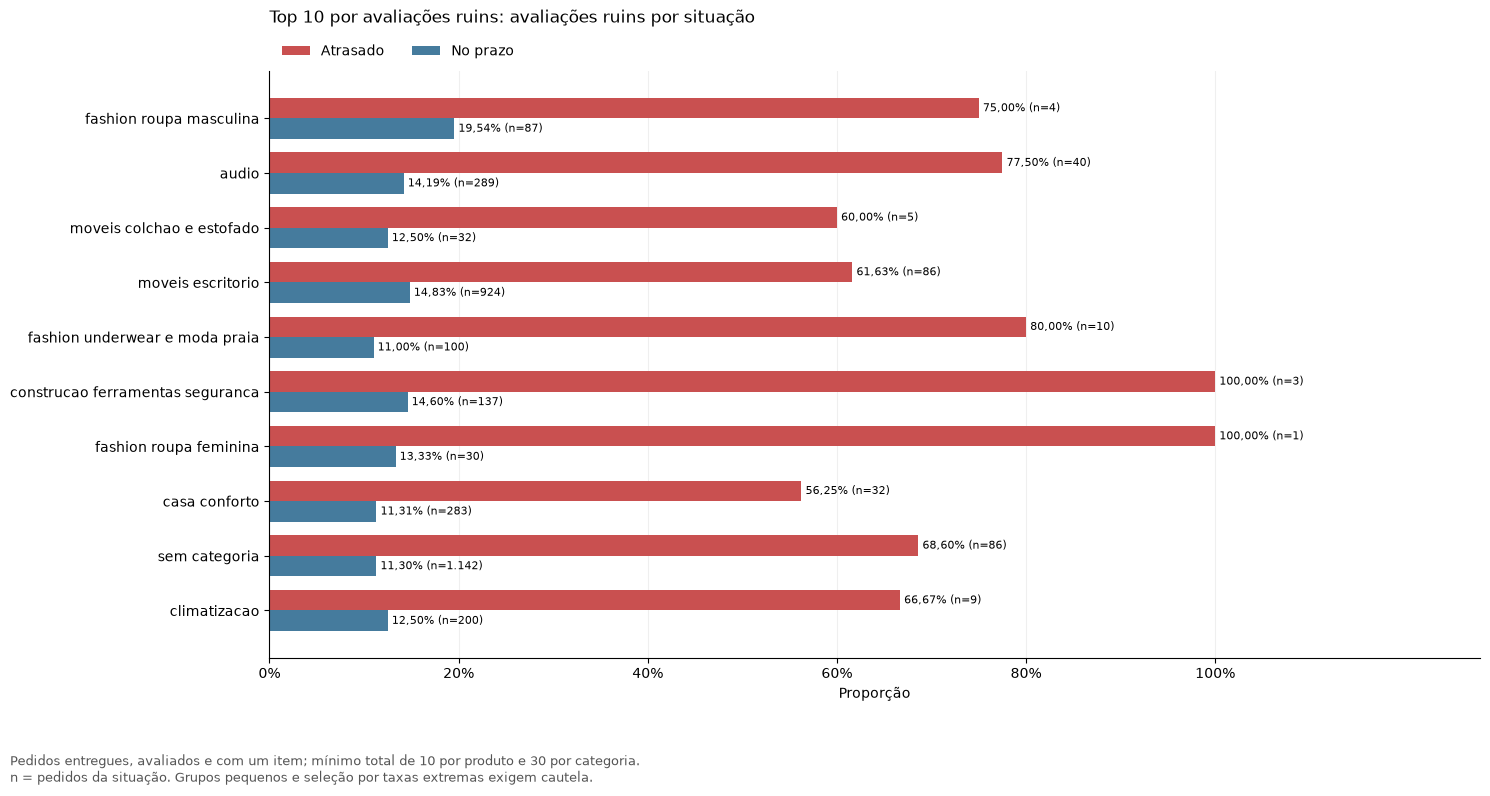

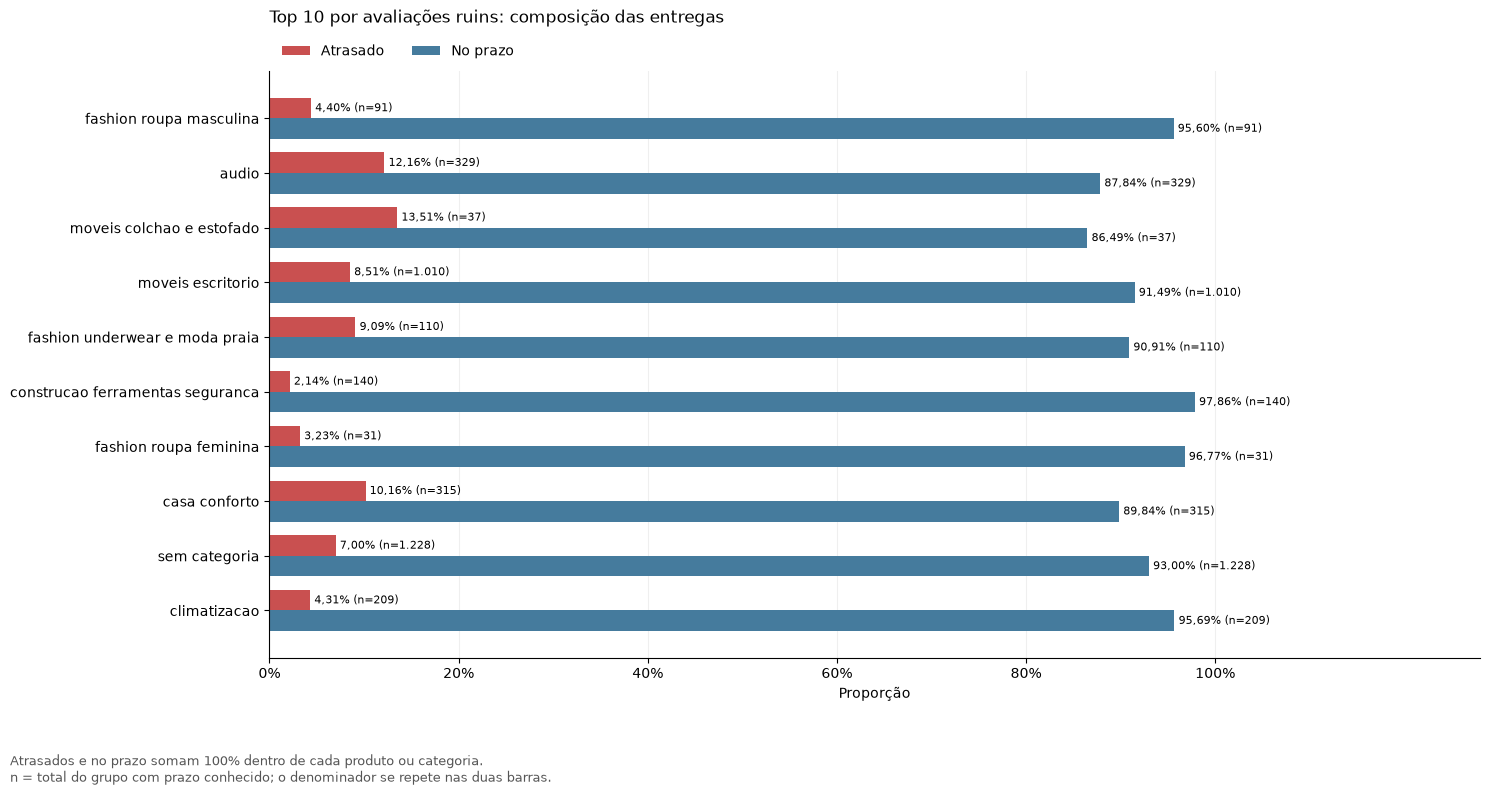

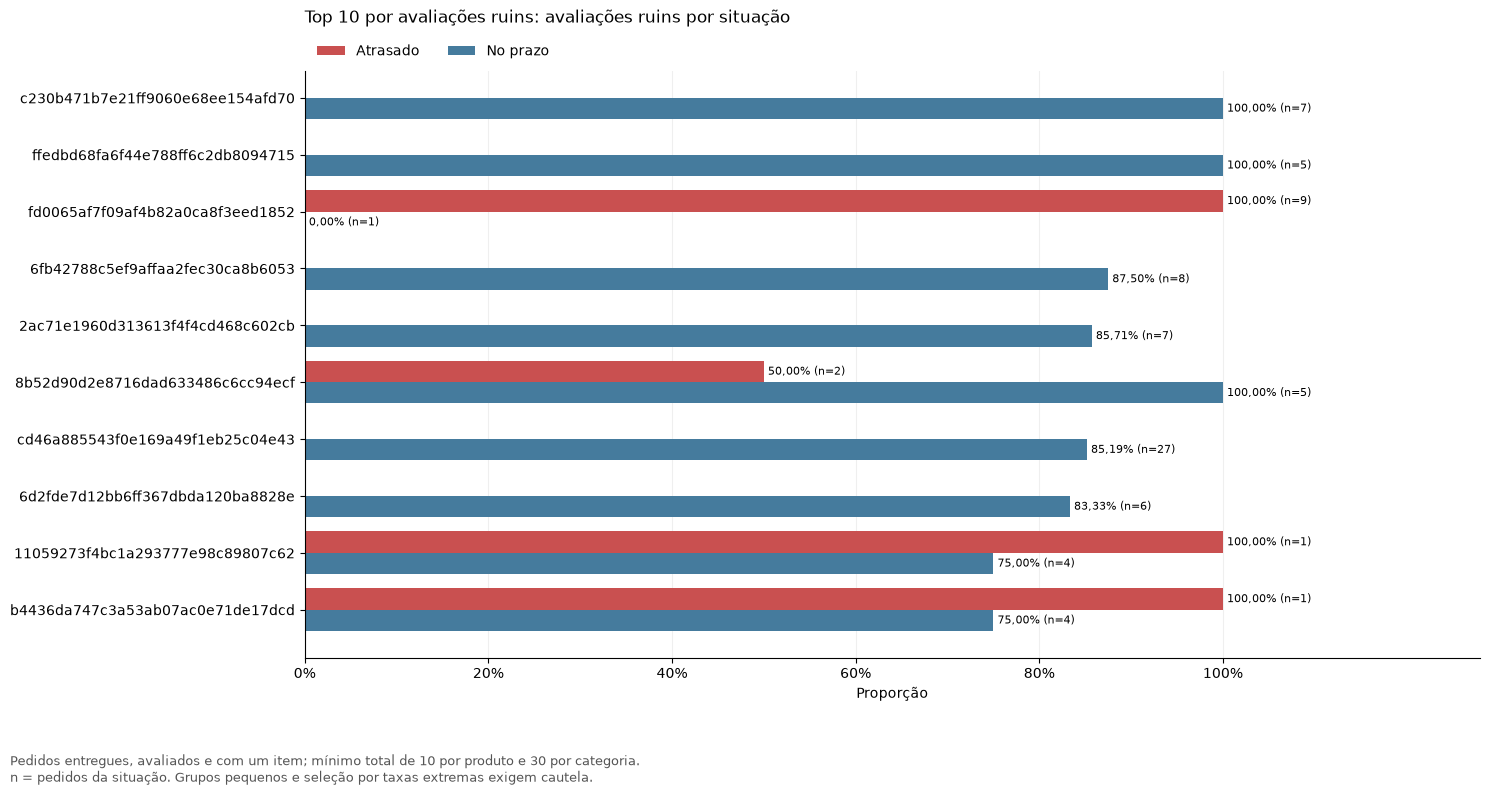

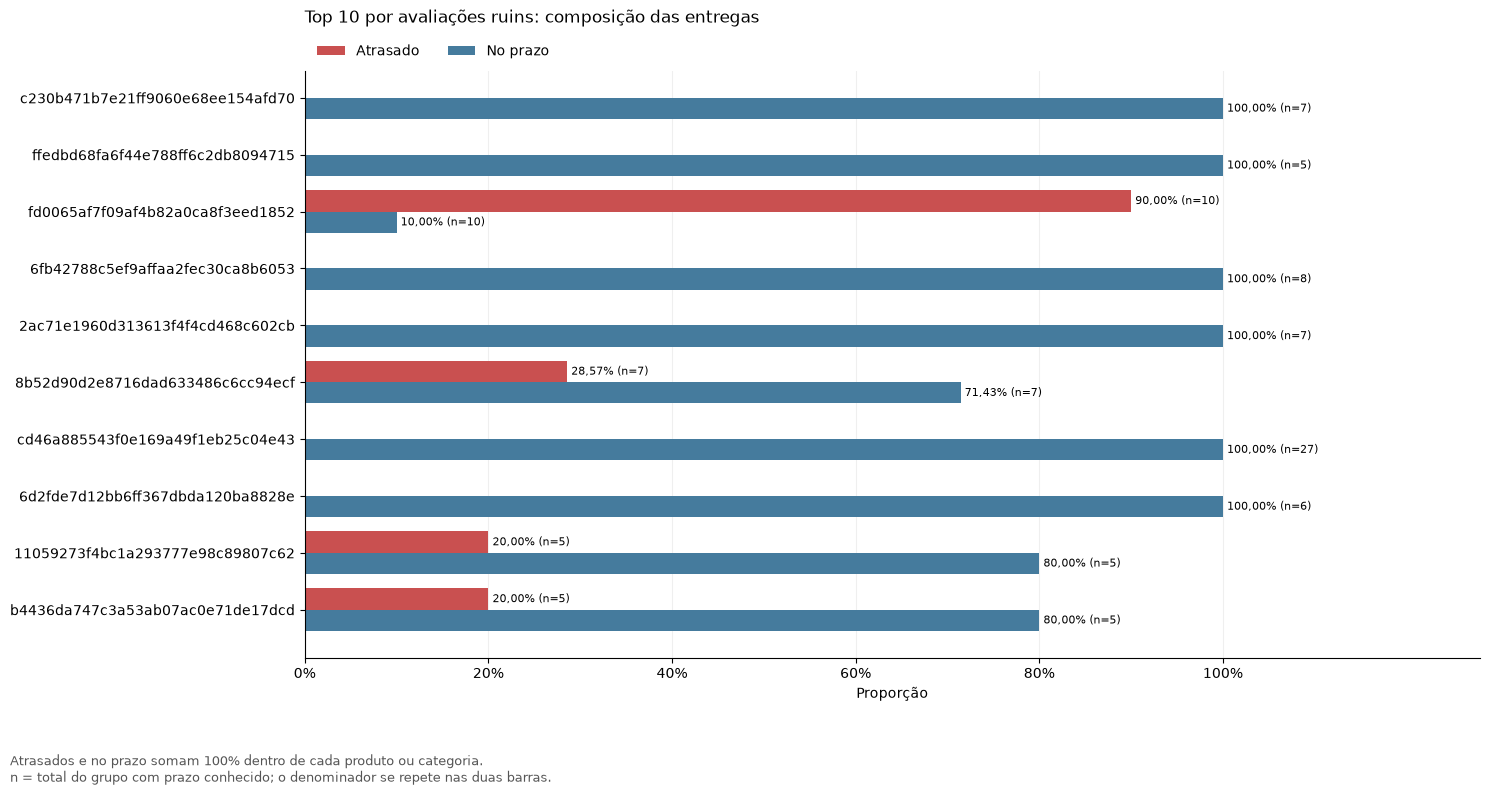

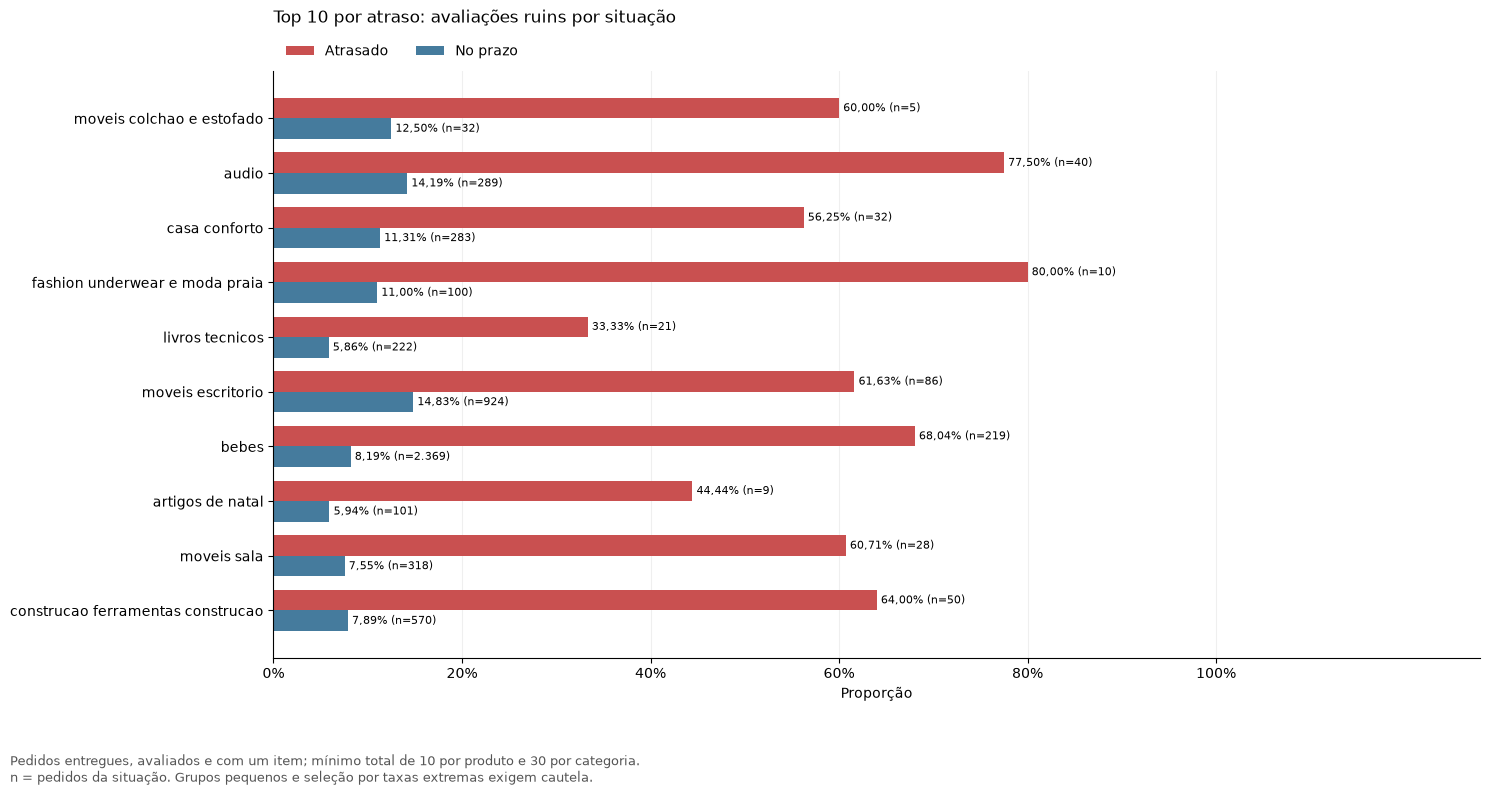

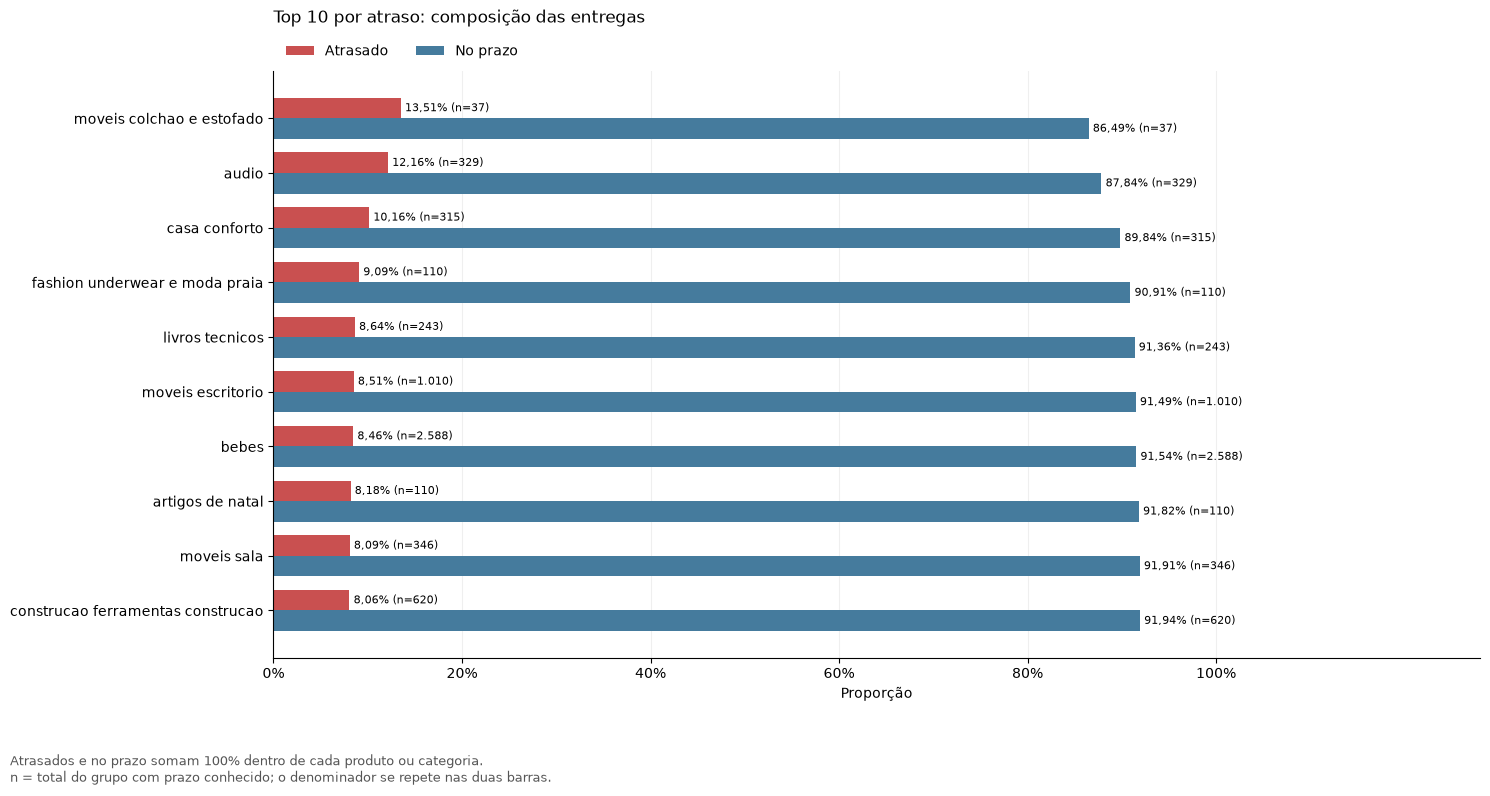

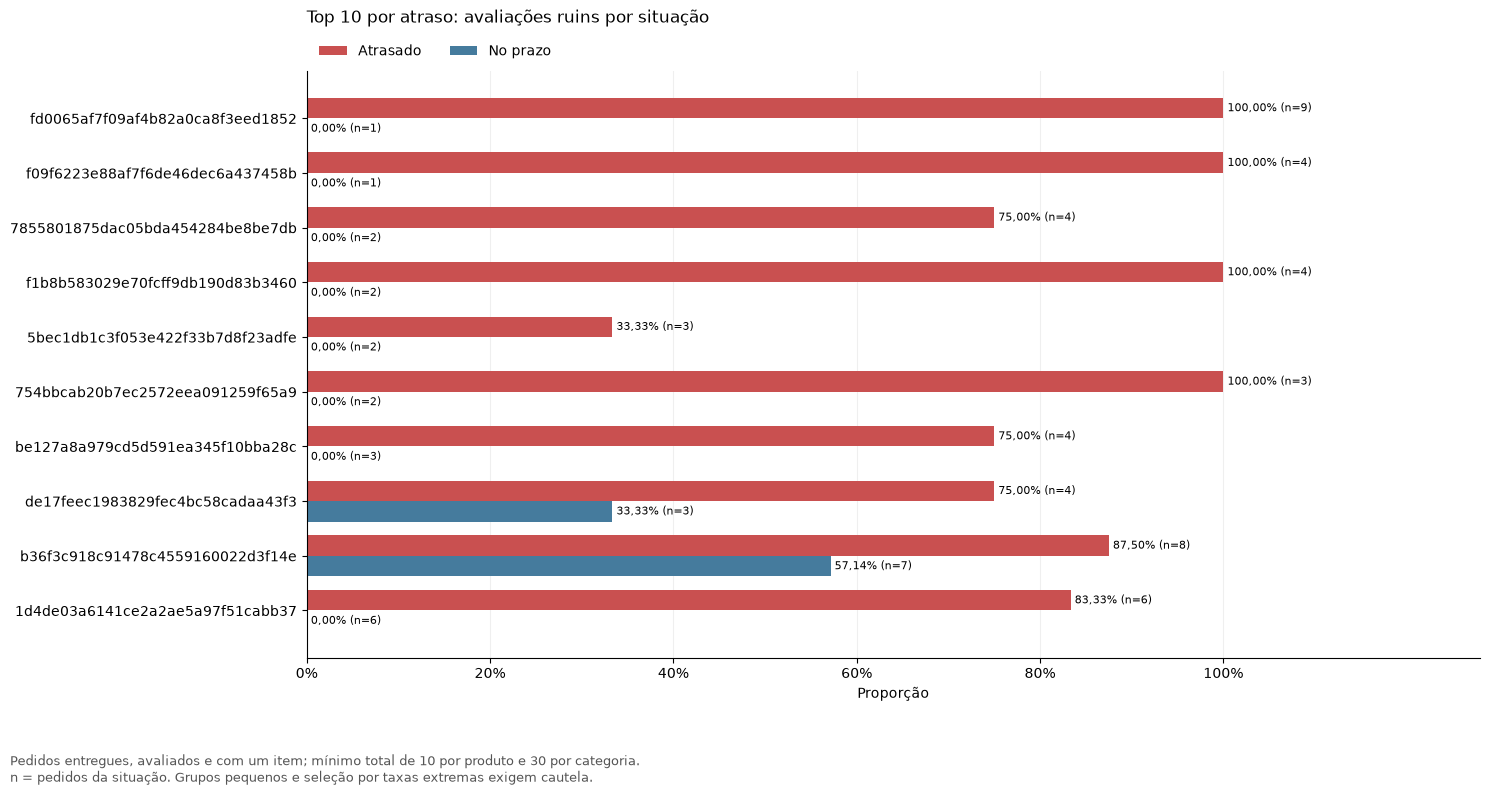

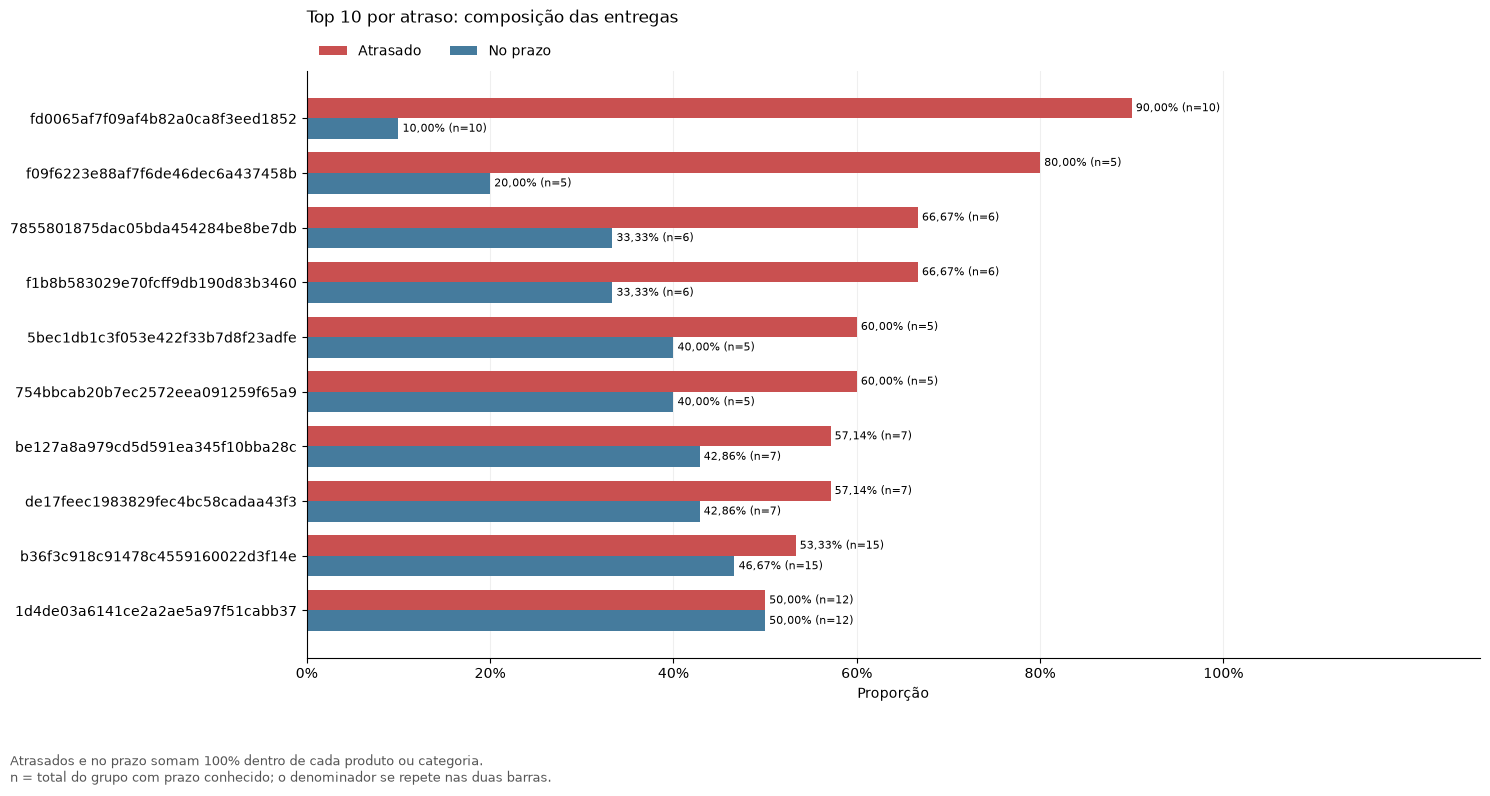

In [7]:
for tabela, grupo, criterio, sufixo in [
    (df_categorias_atraso_avaliacao, 'categoria', 'avaliações ruins', 'categorias_avaliacoes'),
    (df_produtos_atraso_avaliacao, 'product_id', 'avaliações ruins', 'produtos_avaliacoes'),
    (df_categorias_maiores_atrasos, 'categoria', 'atraso', 'categorias_atrasos'),
    (df_produtos_maiores_atrasos, 'product_id', 'atraso', 'produtos_atrasos')
]:
    grafico_situacoes(
        tabela, grupo, 'pct_reviews_ruins', 'quantidade_pedidos',
        f'Top 10 por {criterio}: avaliações ruins por situação',
        f'08_{sufixo}.png',
        'Pedidos entregues, avaliados e com um item; mínimo total de 10 por produto e 30 por categoria.\n'
        'n = pedidos da situação. Grupos pequenos e seleção por taxas extremas exigem cautela.'
    )
    grafico_situacoes(
        tabela, grupo, 'pct_pedidos_situacao', 'pedidos_com_prazo',
        f'Top 10 por {criterio}: composição das entregas',
        f'08_{sufixo}_composicao.png',
        'Atrasados e no prazo somam 100% dentro de cada produto ou categoria.\n'
        'n = total do grupo com prazo conhecido; o denominador se repete nas duas barras.'
    )


## Exportações

Salva as tabelas em Parquet e CSV e os gráficos em PNG.

In [8]:
PASTA_PARQUET = RAIZ_PROJETO / 'outputs' / 'tabelas' / 'parquet'
PASTA_CSV = RAIZ_PROJETO / 'outputs' / 'tabelas' / 'csv'
for pasta in (PASTA_PARQUET, PASTA_CSV, PASTA_GRAFICOS):
    pasta.mkdir(parents=True, exist_ok=True)

tabelas_exportar = {
    '08_produtos_atraso_avaliacao': df_produtos_atraso_avaliacao,
    '08_categorias_atraso_avaliacao': df_categorias_atraso_avaliacao,
    '08_produtos_maiores_atrasos': df_produtos_maiores_atrasos,
    '08_categorias_maiores_atrasos': df_categorias_maiores_atrasos,
}
for nome, original in tabelas_exportar.items():
    tabela = original.reset_index(drop=True).convert_dtypes()
    caminho = PASTA_PARQUET / f'{nome}.parquet'
    tabela.to_parquet(caminho, index=False)
    pd.testing.assert_frame_equal(tabela, pd.read_parquet(caminho), check_exact=True)
    tabela.to_csv(
        PASTA_CSV / f'{nome}.csv', index=False,
        sep=';', decimal=',', encoding='utf-8-sig'
    )
    print(f'Tabela exportada em Parquet e CSV: {nome} ({len(tabela)} linhas)')

for nome, conteudo in graficos_exportar.items():
    (PASTA_GRAFICOS / nome).write_bytes(conteudo)
    print(f'Gráfico exportado: {nome}')


Tabela exportada em Parquet e CSV: 08_produtos_atraso_avaliacao (14 linhas)
Tabela exportada em Parquet e CSV: 08_categorias_atraso_avaliacao (20 linhas)
Tabela exportada em Parquet e CSV: 08_produtos_maiores_atrasos (20 linhas)


Tabela exportada em Parquet e CSV: 08_categorias_maiores_atrasos (20 linhas)
Gráfico exportado: 08_categorias_avaliacoes.png
Gráfico exportado: 08_categorias_avaliacoes_composicao.png
Gráfico exportado: 08_produtos_avaliacoes.png
Gráfico exportado: 08_produtos_avaliacoes_composicao.png
Gráfico exportado: 08_categorias_atrasos.png
Gráfico exportado: 08_categorias_atrasos_composicao.png
Gráfico exportado: 08_produtos_atrasos.png
Gráfico exportado: 08_produtos_atrasos_composicao.png
